# 02 — Baseline and ensemble models on CICIDS2017 (improved)

## Research question

How effectively can network-flow statistics distinguish benign traffic from cyberattacks and separate attack families, and how much can evaluation design overstate that performance?

The required baseline is a class-weighted multinomial **Logistic Regression** model. Five tree-based ensemble methods are included as preliminary comparisons for the next capstone stage: Random Forest, Extra Trees, HistGradientBoosting, XGBoost, and LightGBM.

**Setup based on notebook 01**

- Flows labelled `... - Attempted` have no effective attack payload, so they are folded into `BENIGN`.
- Identifier and leakage-prone columns are dropped: `id`, `Flow ID`, `Src IP`, `Dst IP`, `Src Port`, `Timestamp`, and `Attempted Category`.
- Infinite values are replaced with the corresponding finite column maximum, constant columns are dropped, and exact feature/label duplicates are removed.
- Every effective attack class remains separate.
- Two evaluations are reported:
  1. **Random split:** stratified 80/20. This common setup is optimistic because flows from the same attack burst can enter both training and test sets.
  2. **Time-ordered split:** within each class, the earliest 80% trains the model and the latest 20% tests it. Every class remains represented, but the model cannot train on the future portion of a burst.
- Models use baseline or near-default settings rather than tuned hyperparameters.
- HistGradientBoosting and LightGBM use balanced class weights because early unweighted runs collapsed on the rarest classes.
- The source CSV files are read only.


In [1]:
import glob, os, time, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, FunctionTransformer, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
warnings.filterwarnings('ignore', category=UserWarning)
pd.set_option('display.width', 200); sns.set_theme(style='whitegrid')
DATA = '../Data/archive/CICIDS2017_improved'
RS = 42; N_JOBS = -1


## 1. Load and clean

In [2]:
df = pd.concat([pd.read_csv(f) for f in sorted(glob.glob(f'{DATA}/*.csv'))], ignore_index=True)
df['y'] = df['Label'].where(~df['Label'].str.endswith(' - Attempted'), 'BENIGN')
df['ts'] = pd.to_datetime(df['Timestamp'])
drop = ['id', 'Flow ID', 'Src IP', 'Dst IP', 'Src Port', 'Timestamp', 'Attempted Category', 'Label']
X = df.drop(columns=drop + ['y', 'ts']).replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.max())
const = [c for c in X if X[c].nunique() <= 1]
X = X.drop(columns=const)
FEATURES = list(X.columns)
data = X.assign(y=df['y'].values, ts=df['ts'].values)
n0 = len(data)
data = data.drop_duplicates(subset=FEATURES + ['y']).reset_index(drop=True)   # keep first occurrence (its timestamp)
print(f'{len(FEATURES)} features | constant dropped: {const} | duplicates removed: {n0-len(data):,} | rows: {len(data):,}')
del df, X
LABELS = sorted(data['y'].unique(), key=lambda c: (c != 'BENIGN', c))
enc = LabelEncoder().fit(LABELS)
data['y'].value_counts().to_frame('flows')

83 features | constant dropped: [] | duplicates removed: 258,629 | rows: 1,841,347


,flows
y,
BENIGN,1434950
DoS Hulk,158468
DDoS,95144
Portscan,90620
Infiltration - Portscan,41179
DoS GoldenEye,7567
FTP-Patator,3972
DoS Slowloris,3859
SSH-Patator,2961


## 2. Splits

In [3]:
# 1) stratified random 80/20
tr_r, te_r = train_test_split(data.index, test_size=0.2, stratify=data['y'], random_state=RS)
# 2) time-ordered: per class, earliest 80% -> train, latest 20% -> test
rank = data.groupby('y')['ts'].rank(method='first', pct=True)
tr_t, te_t = data.index[rank <= 0.8], data.index[rank > 0.8]
SPLITS = {'random': (tr_r, te_r), 'time-ordered': (tr_t, te_t)}
for k, (a, b) in SPLITS.items(): print(f'{k:13s} train {len(a):,}  test {len(b):,}')
Xall = data[FEATURES].astype('float32').values
yall = enc.transform(data['y'])

random        train 1,473,077  test 368,270
time-ordered  train 1,473,071  test 368,276


## 3. Models

In [4]:
signed_log = FunctionTransformer(lambda a: np.sign(a) * np.log1p(np.abs(a)))
def make_models():
    return {
        'LogReg (baseline)': make_pipeline(signed_log, StandardScaler(),
                               LogisticRegression(max_iter=300, class_weight='balanced')),
        'RandomForest':  RandomForestClassifier(n_estimators=100, n_jobs=N_JOBS, random_state=RS),
        'ExtraTrees':    ExtraTreesClassifier(n_estimators=100, n_jobs=N_JOBS, random_state=RS),
        'HistGB':        HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, class_weight='balanced',
                                                      early_stopping=False, random_state=RS),
        'XGBoost':       XGBClassifier(n_estimators=200, max_depth=8, learning_rate=0.1, tree_method='hist',
                                       n_jobs=N_JOBS, random_state=RS),
        'LightGBM':      LGBMClassifier(n_estimators=200, learning_rate=0.1, num_leaves=63, n_jobs=N_JOBS,
                                        class_weight='balanced', random_state=RS, verbose=-1),
    }

In [5]:
results, preds, timing, fitted = [], {}, [], {}
for split, (tr, te) in SPLITS.items():
    for name, m in make_models().items():
        t = time.time(); m.fit(Xall[tr], yall[tr]); fit_s = time.time() - t
        t = time.time(); p = m.predict(Xall[te]); pred_s = time.time() - t
        preds[(split, name)] = p
        if split == 'random': fitted[name] = m
        pr, rc, f1, sup = precision_recall_fscore_support(yall[te], p, labels=enc.transform(LABELS), zero_division=0)
        results.append(pd.DataFrame({'split': split, 'model': name, 'class': LABELS,
                                     'precision': pr, 'recall': rc, 'f1': f1, 'support': sup}))
        timing.append({'split': split, 'model': name, 'fit_s': round(fit_s), 'predict_s': round(pred_s, 1)})
        print(f'{split:13s} {name:18s} fit {fit_s:6.0f}s  macro-F1 {f1.mean():.4f}')
metrics = pd.concat(results, ignore_index=True)
metrics.to_csv('02_per_class_metrics.csv', index=False)
pd.DataFrame(timing).pivot(index='model', columns='split', values='fit_s').rename(columns=lambda c: f'fit seconds ({c})')

random        LogReg (baseline)  fit    126s  macro-F1 0.7969


random        RandomForest       fit     77s  macro-F1 0.9342


random        ExtraTrees         fit     22s  macro-F1 0.9552


random        HistGB             fit    250s  macro-F1 0.9854


random        XGBoost            fit     72s  macro-F1 0.9858


...

time-ordered  ExtraTrees         fit     20s  macro-F1 0.8924


time-ordered  HistGB             fit    241s  macro-F1 0.9236


time-ordered  XGBoost            fit     77s  macro-F1 0.9108


time-ordered  LightGBM           fit     72s  macro-F1 0.9182


split,fit seconds (random),fit seconds (time-ordered)
model,,
ExtraTrees,22,20
HistGB,250,241
LightGBM,71,72
LogReg (baseline),126,116
RandomForest,77,69
XGBoost,72,77


## 4. Evaluation metric and overall comparison

**Primary metric: macro F1.** F1 is the harmonic mean of precision and recall, so it penalizes a model that attains high recall by producing many false alarms or high precision by missing attacks. Macro F1 calculates F1 separately for every class and then gives each class equal weight. This is appropriate because benign flows dominate the dataset and several security-relevant attacks are rare.

Accuracy and weighted F1 are reported only as secondary context because both are dominated by `BENIGN`. A macro F1 of 0.73 means the unweighted average class-level F1 is 0.73; it does **not** mean that 73% of all flows were classified correctly.


macro_precision  macro_recall  macro_f1  weighted_f1  attack_macro_f1
split        model                                                                                   
random       ExtraTrees                  0.9846        0.9373    0.9552       0.9926           0.9522
             HistGB                      0.9897        0.9819    0.9854       0.9952           0.9844
             LightGBM                    0.9884        0.9722    0.9787       0.9947           0.9773
             LogReg (baseline)           0.7553        0.9733    0.7969       0.9891           0.7836
             RandomForest                0.9846        0.9121    0.9342       0.9925           0.9298
             XGBoost                     0.9912        0.9811    0.9858       0.9955           0.9848
time-ordered ExtraTrees                  0.9753        0.8464    0.8924       0.9900           0.8853
             HistGB                      0.9359        0.9179    0.9236       0.9907           0.9186
             LightGBM                    0.9340        0.9086    0.9182       0.9894           0.9129
             LogReg (baseline)           0.6868        0.9457    0.7278       0.9841           0.7101
             RandomForest                0.9725        0.8501    0.8908       0.9881           0.8836
             XGBoost                     0.9874        0.8690    0.9108       0.9910           0.9051

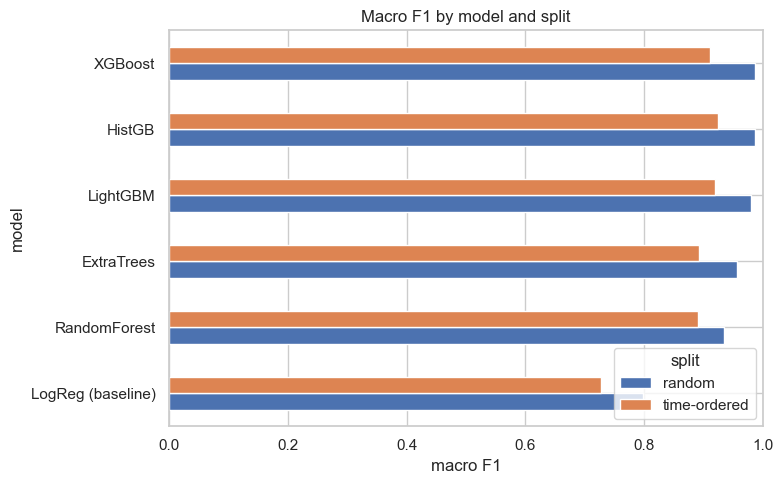

In [6]:
def summarise(d):
    return pd.Series({'macro_precision': d.precision.mean(), 'macro_recall': d.recall.mean(),
                      'macro_f1': d.f1.mean(), 'weighted_f1': np.average(d.f1, weights=d.support),
                      'attack_macro_f1': d[d['class'] != 'BENIGN'].f1.mean()})
summary = metrics.groupby(['split', 'model']).apply(summarise, include_groups=False)
summary.to_csv('02_summary.csv')
display(summary.round(4))
ax = summary['macro_f1'].unstack(0).sort_values('random').plot.barh(figsize=(8, 5))
ax.set_xlim(0, 1); ax.set_xlabel('macro F1'); ax.set_title('Macro F1 by model and split'); plt.tight_layout(); plt.show()

## 5. Per-class F1

--- random split ---


model,ExtraTrees,HistGB,LightGBM,LogReg (baseline),RandomForest,XGBoost,support (test)
class,,,,,,,
BENIGN,1.0000,1.0000,1.0000,0.9963,1.0000,1.0000,286990
Botnet,1.0000,1.0000,1.0000,0.8909,1.0000,1.0000,147
DDoS,1.0000,1.0000,1.0000,0.9991,1.0000,1.0000,19029
DoS GoldenEye,0.9997,0.9993,0.9993,0.9464,0.9990,0.9997,1513
DoS Hulk,1.0000,1.0000,1.0000,0.9990,1.0000,1.0000,31694
DoS Slowhttptest,0.9986,0.9986,0.9986,0.7344,0.9986,0.9971,348
DoS Slowloris,0.9987,1.0000,1.0000,0.9797,0.9987,0.9994,772
FTP-Patator,1.0000,1.0000,1.0000,0.9956,1.0000,1.0000,794
Heartbleed,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,2


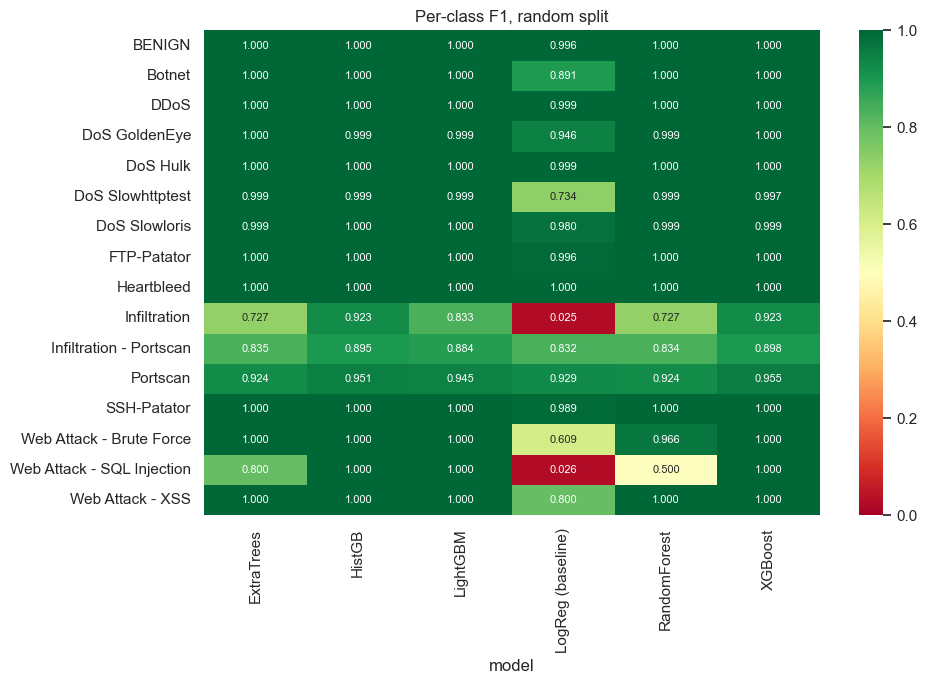

--- time-ordered split ---


model,ExtraTrees,HistGB,LightGBM,LogReg (baseline),RandomForest,XGBoost,support (test)
class,,,,,,,
BENIGN,0.9989,0.9982,0.9977,0.9937,0.9977,0.9971,286990
Botnet,1.0000,1.0000,1.0000,0.6592,1.0000,1.0000,148
DDoS,0.9994,0.9994,0.9994,0.9990,0.9994,0.9994,19029
DoS GoldenEye,0.9944,0.9993,0.9957,0.9237,0.9947,0.9990,1514
DoS Hulk,0.9997,1.0000,0.9997,0.9986,0.9997,0.9997,31694
DoS Slowhttptest,0.5675,0.4193,0.3146,0.4686,0.5663,0.5378,348
DoS Slowloris,0.7365,0.7460,0.7523,0.6672,0.7500,0.7546,772
FTP-Patator,0.9975,1.0000,0.9994,0.9956,0.9937,0.9975,795
Heartbleed,0.8000,1.0000,1.0000,0.6667,1.0000,0.8000,3


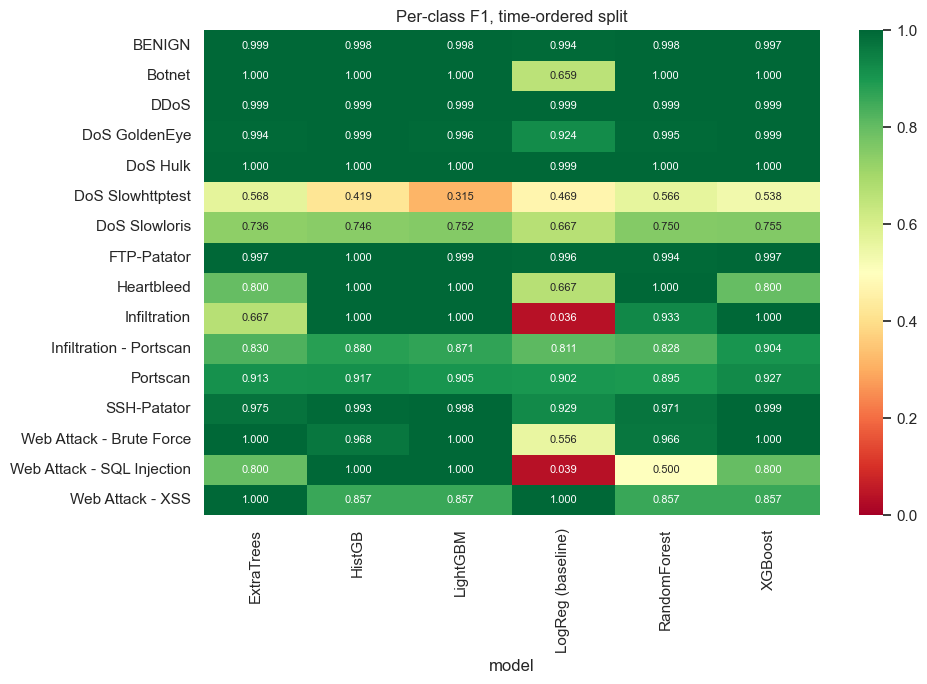

In [7]:
for split in SPLITS:
    f1 = metrics[metrics.split == split].pivot(index='class', columns='model', values='f1').reindex(LABELS)
    f1['support (test)'] = metrics[(metrics.split == split)].drop_duplicates('class').set_index('class')['support']
    print(f'--- {split} split ---'); display(f1.round(4))
    fig, ax = plt.subplots(figsize=(10, 7))
    sns.heatmap(f1.drop(columns='support (test)'), annot=True, fmt='.3f', cmap='RdYlGn', vmin=0, vmax=1, ax=ax,
                annot_kws={'fontsize': 8})
    ax.set_title(f'Per-class F1, {split} split'); ax.set_ylabel(''); plt.tight_layout(); plt.show()

## 6. Per-class precision, recall, F1 for every model\nFull tables, also saved to `02_per_class_metrics.csv`.

In [8]:
for (split, name), p in preds.items():
    te = SPLITS[split][1]
    print(f'===== {name}  |  {split} split =====')
    print(classification_report(yall[te], p, labels=enc.transform(LABELS), target_names=LABELS, digits=4, zero_division=0))

===== LogReg (baseline)  |  random split =====
                            precision    recall  f1-score   support

                    BENIGN     0.9999    0.9927    0.9963    286990
                    Botnet     0.8033    1.0000    0.8909       147
                      DDoS     0.9986    0.9997    0.9991     19029
             DoS GoldenEye     0.8999    0.9980    0.9464      1513
                  DoS Hulk     0.9982    0.9997    0.9990     31694
          DoS Slowhttptest     0.5812    0.9971    0.7344       348
             DoS Slowloris     0.9602    1.0000    0.9797       772
               FTP-Patator     0.9913    1.0000    0.9956       794
                Heartbleed     1.0000    1.0000    1.0000         2
              Infiltration     0.0126    0.8571    0.0248         7
   Infiltration - Portscan     0.8053    0.8610    0.8322      8236
                  Portscan     0.9240    0.9337    0.9288     18124
               SSH-Patator     0.9785    1.0000    0.9891       592


                            precision    recall  f1-score   support

                    BENIGN     0.9999    1.0000    1.0000    286990
                    Botnet     1.0000    1.0000    1.0000       147
                      DDoS     1.0000    1.0000    1.0000     19029
             DoS GoldenEye     1.0000    0.9980    0.9990      1513
                  DoS Hulk     1.0000    0.9999    1.0000     31694
          DoS Slowhttptest     0.9971    1.0000    0.9986       348
             DoS Slowloris     1.0000    0.9974    0.9987       772
               FTP-Patator     1.0000    1.0000    1.0000       794
                Heartbleed     1.0000    1.0000    1.0000         2
              Infiltration     1.0000    0.5714    0.7273         7
   Infiltration - Portscan     0.8310    0.8371    0.8340      8236
                  Portscan     0.9257    0.9225    0.9241     18124
               SSH-Patator     1.0000    1.0000    1.0000       592
  Web Attack - Brute Force     1.0000    0.9333

                            precision    recall  f1-score   support

                    BENIGN     1.0000    1.0000    1.0000    286990
                    Botnet     1.0000    1.0000    1.0000       147
                      DDoS     1.0000    1.0000    1.0000     19029
             DoS GoldenEye     0.9993    0.9993    0.9993      1513
                  DoS Hulk     1.0000    1.0000    1.0000     31694
          DoS Slowhttptest     0.9971    1.0000    0.9986       348
             DoS Slowloris     1.0000    1.0000    1.0000       772
               FTP-Patator     1.0000    1.0000    1.0000       794
                Heartbleed     1.0000    1.0000    1.0000         2
              Infiltration     1.0000    0.8571    0.9231         7
   Infiltration - Portscan     0.8806    0.9094    0.8948      8236
                  Portscan     0.9582    0.9440    0.9510     18124
               SSH-Patator     1.0000    1.0000    1.0000       592
  Web Attack - Brute Force     1.0000    1.0000

                            precision    recall  f1-score   support

                    BENIGN     1.0000    1.0000    1.0000    286990
                    Botnet     1.0000    1.0000    1.0000       147
                      DDoS     1.0000    1.0000    1.0000     19029
             DoS GoldenEye     0.9993    0.9993    0.9993      1513
                  DoS Hulk     1.0000    1.0000    1.0000     31694
          DoS Slowhttptest     0.9971    1.0000    0.9986       348
             DoS Slowloris     1.0000    1.0000    1.0000       772
               FTP-Patator     1.0000    1.0000    1.0000       794
                Heartbleed     1.0000    1.0000    1.0000         2
              Infiltration     1.0000    0.7143    0.8333         7
   Infiltration - Portscan     0.8610    0.9076    0.8837      8236
                  Portscan     0.9569    0.9334    0.9450     18124
               SSH-Patator     1.0000    1.0000    1.0000       592
  Web Attack - Brute Force     1.0000    1.0000

                            precision    recall  f1-score   support

                    BENIGN     0.9978    1.0000    0.9989    286990
                    Botnet     1.0000    1.0000    1.0000       148
                      DDoS     1.0000    0.9989    0.9994     19029
             DoS GoldenEye     0.9889    1.0000    0.9944      1514
                  DoS Hulk     0.9995    1.0000    0.9997     31694
          DoS Slowhttptest     0.8896    0.4167    0.5675       348
             DoS Slowloris     1.0000    0.5829    0.7365       772
               FTP-Patator     1.0000    0.9950    0.9975       795
                Heartbleed     1.0000    0.6667    0.8000         3
              Infiltration     1.0000    0.5000    0.6667         8
   Infiltration - Portscan     0.7879    0.8762    0.8297      8236
                  Portscan     0.9403    0.8880    0.9134     18124
               SSH-Patator     1.0000    0.9511    0.9749       593
  Web Attack - Brute Force     1.0000    1.0000

                            precision    recall  f1-score   support

                    BENIGN     0.9978    0.9963    0.9971    286990
                    Botnet     1.0000    1.0000    1.0000       148
                      DDoS     0.9999    0.9989    0.9994     19029
             DoS GoldenEye     0.9980    1.0000    0.9990      1514
                  DoS Hulk     0.9995    0.9999    0.9997     31694
          DoS Slowhttptest     1.0000    0.3678    0.5378       348
             DoS Slowloris     0.9958    0.6075    0.7546       772
               FTP-Patator     1.0000    0.9950    0.9975       795
                Heartbleed     1.0000    0.6667    0.8000         3
              Infiltration     1.0000    1.0000    1.0000         8
   Infiltration - Portscan     0.9037    0.9052    0.9045      8236
                  Portscan     0.9040    0.9514    0.9271     18124
               SSH-Patator     1.0000    0.9983    0.9992       593
  Web Attack - Brute Force     1.0000    1.0000

## 7. Confusion matrices\nColour is row-normalised (recall for each true class); numbers are raw counts.

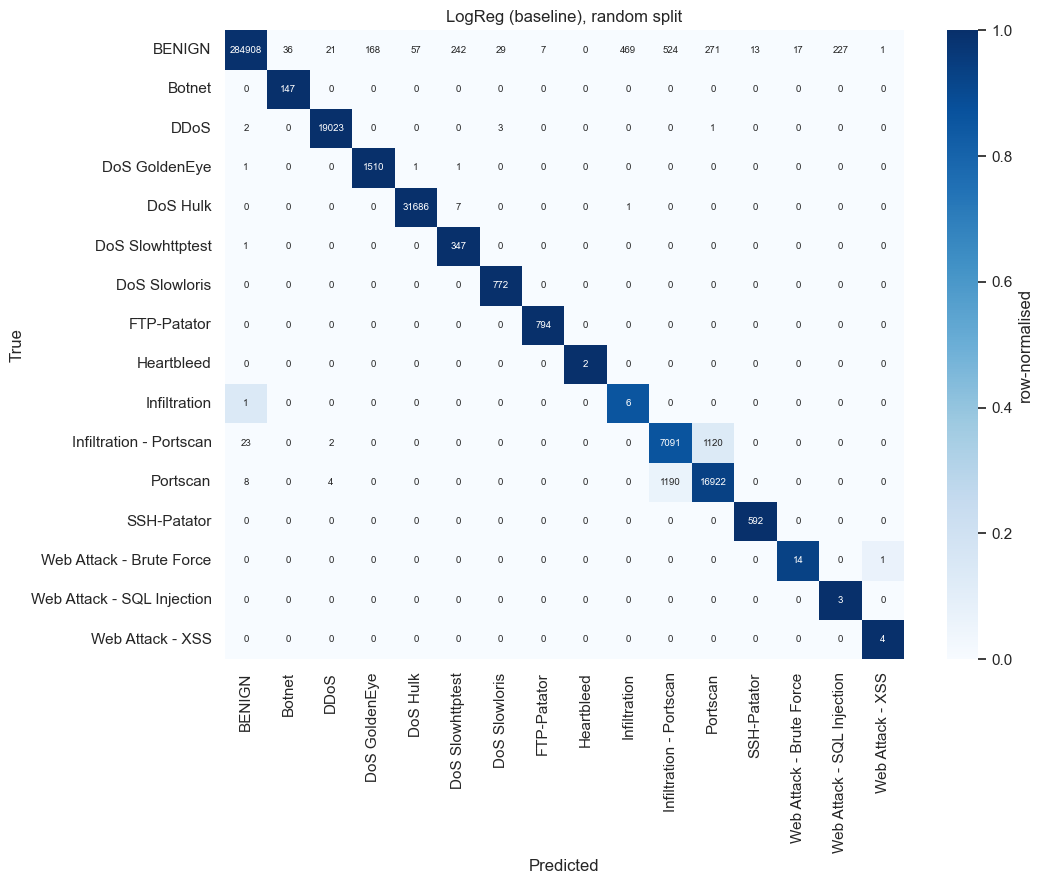

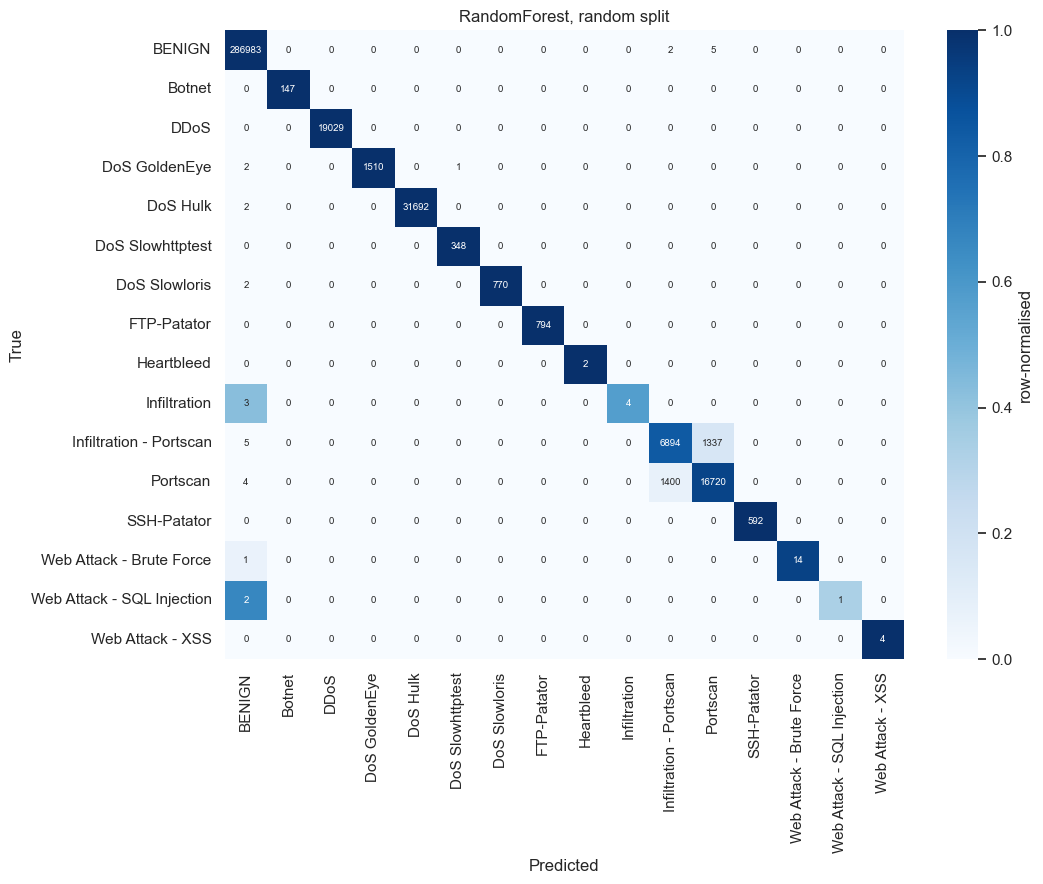

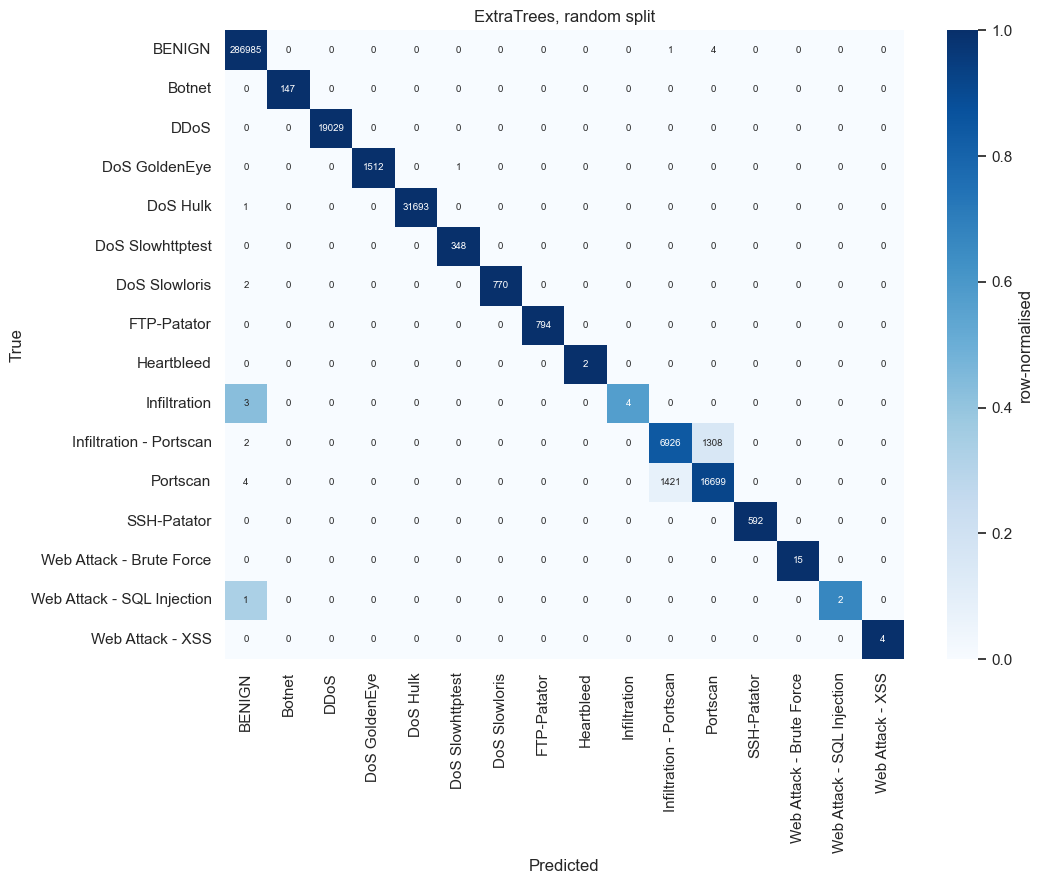

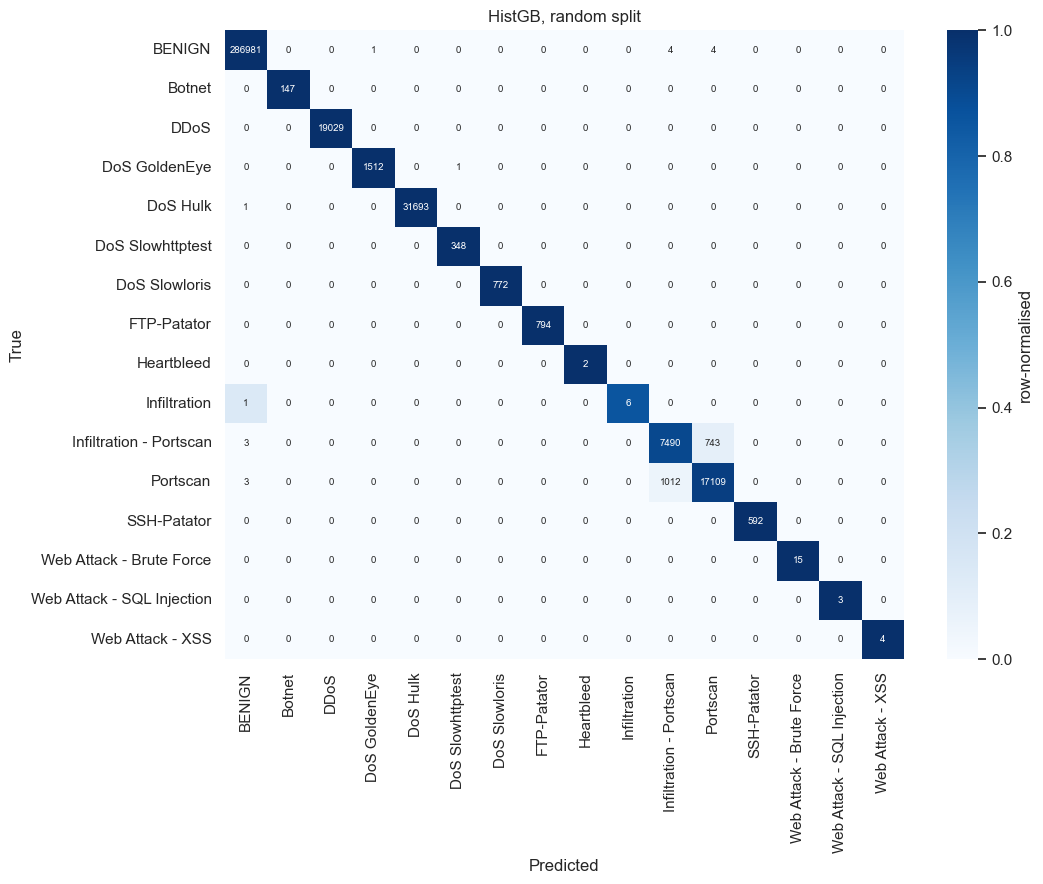

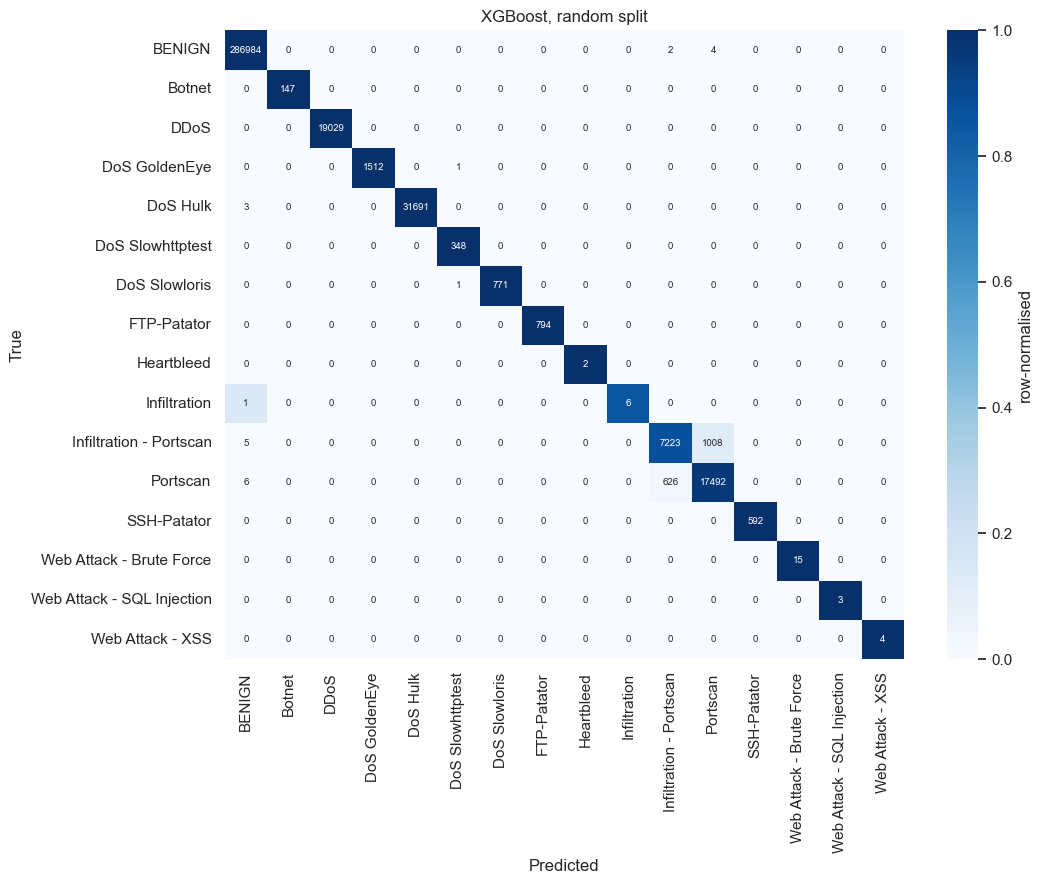

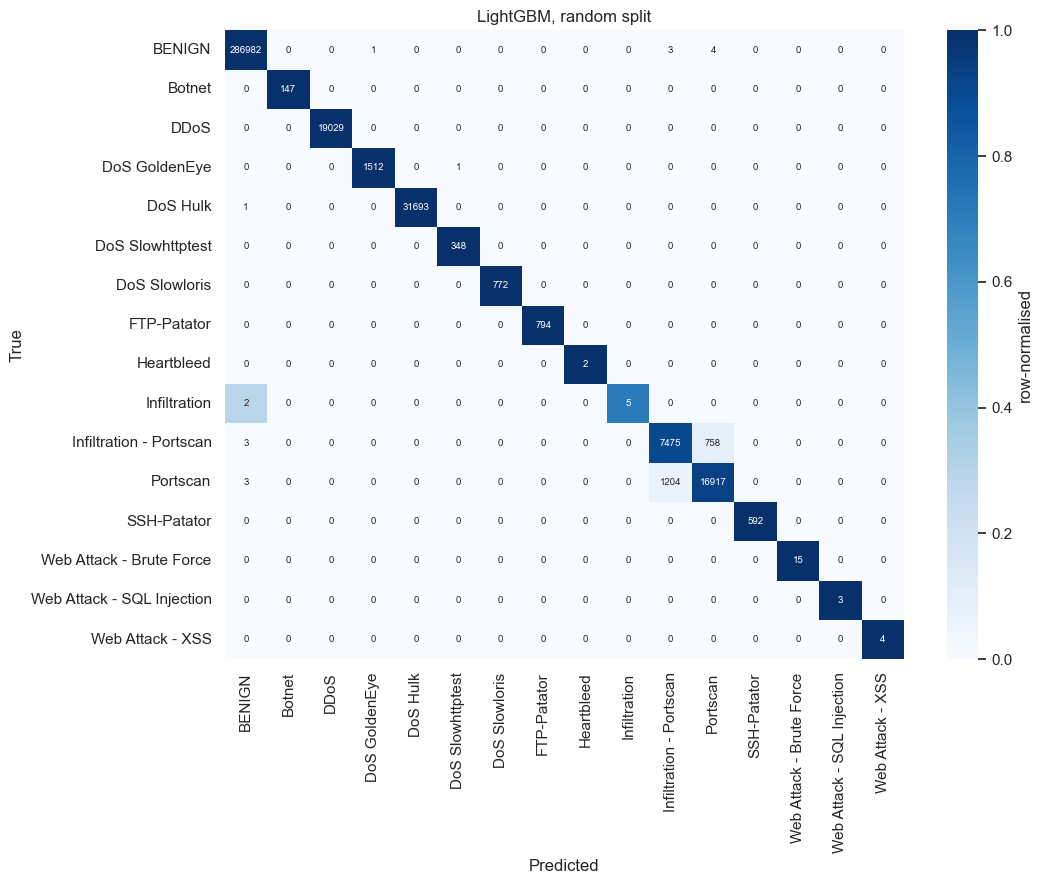

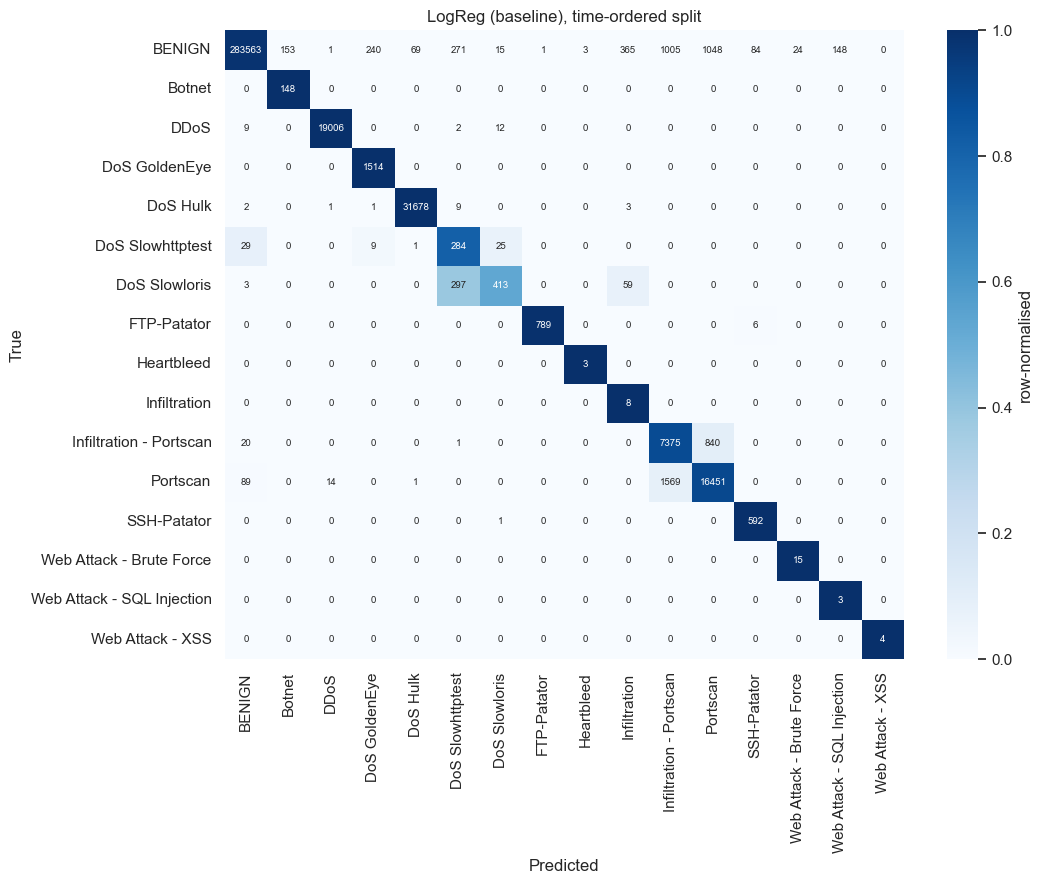

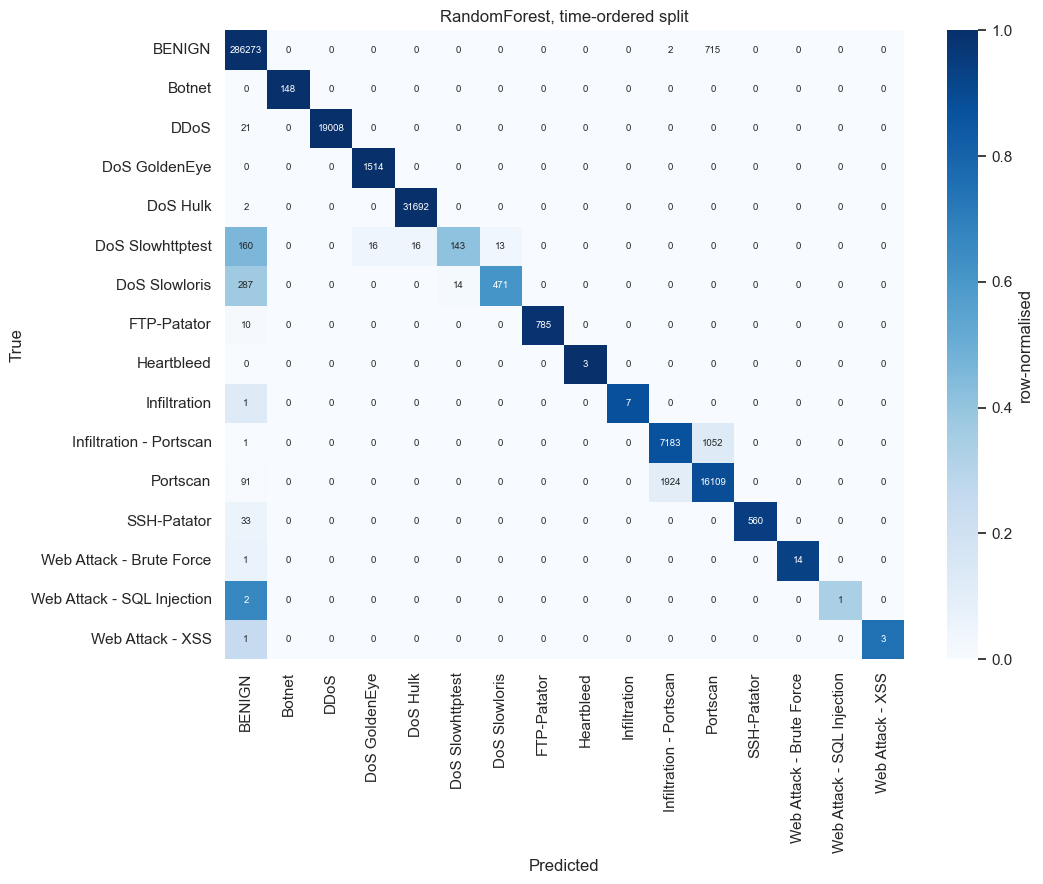

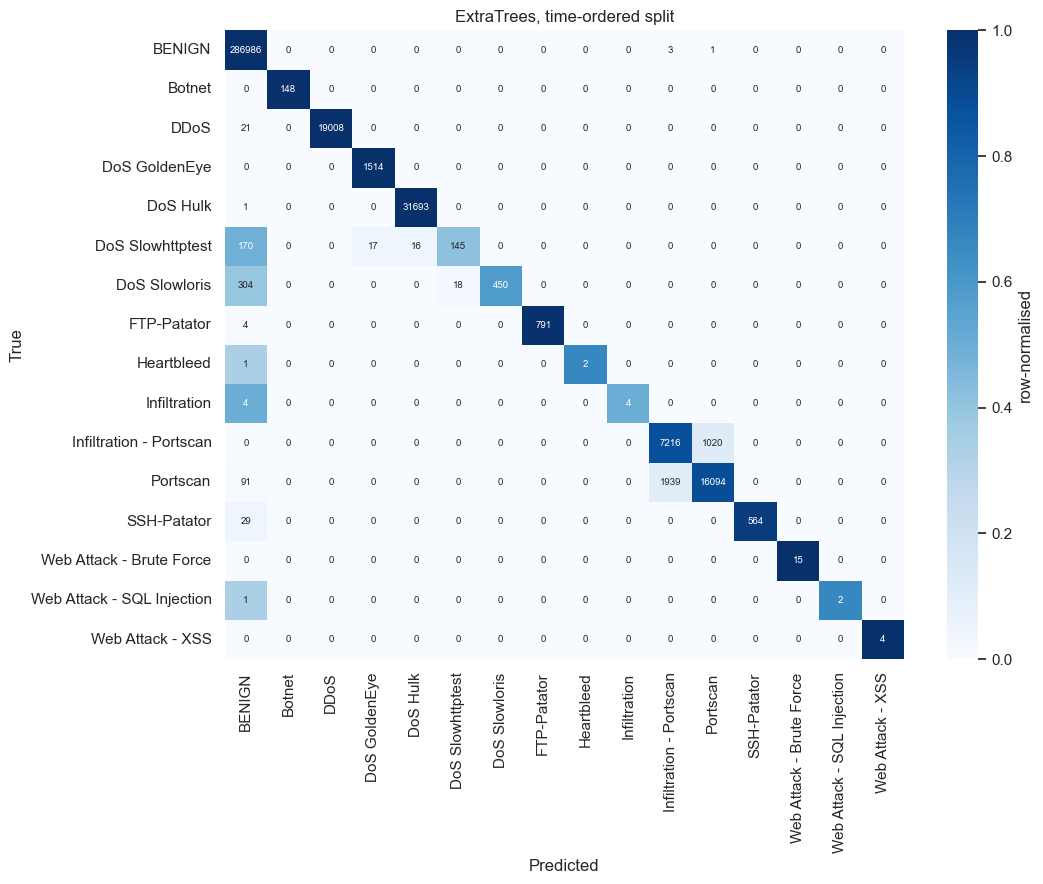

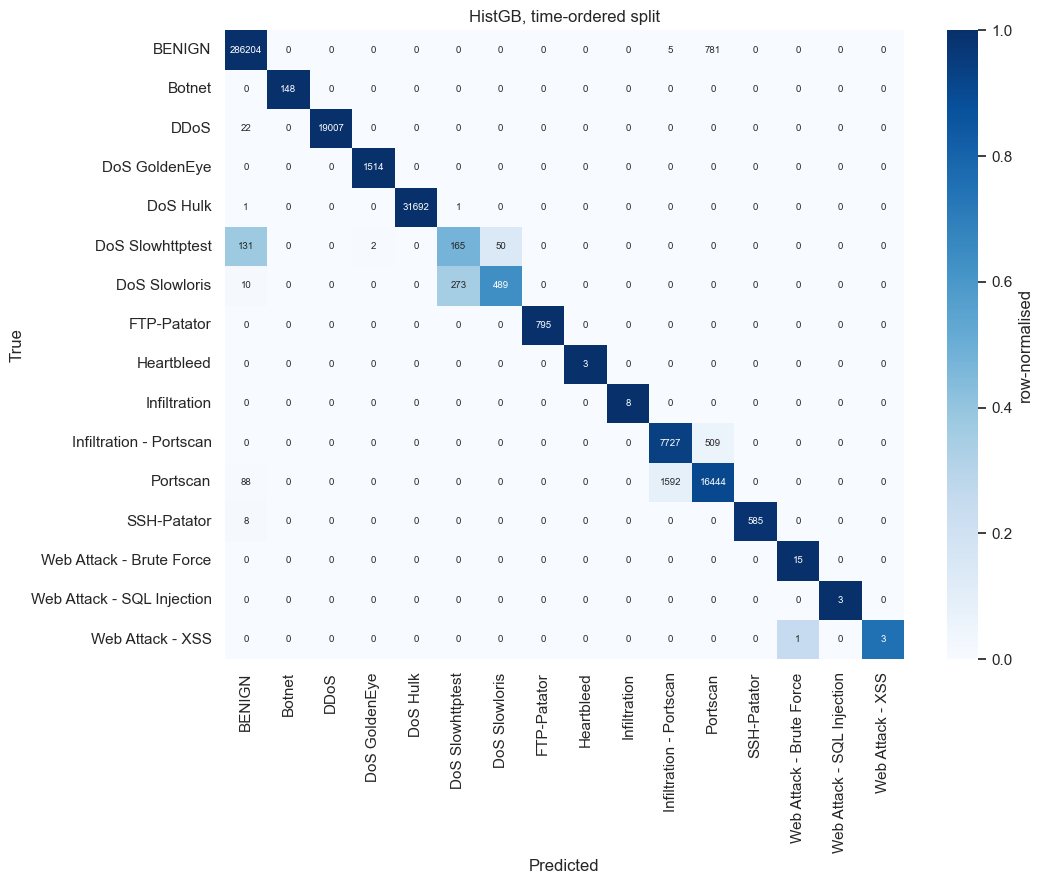

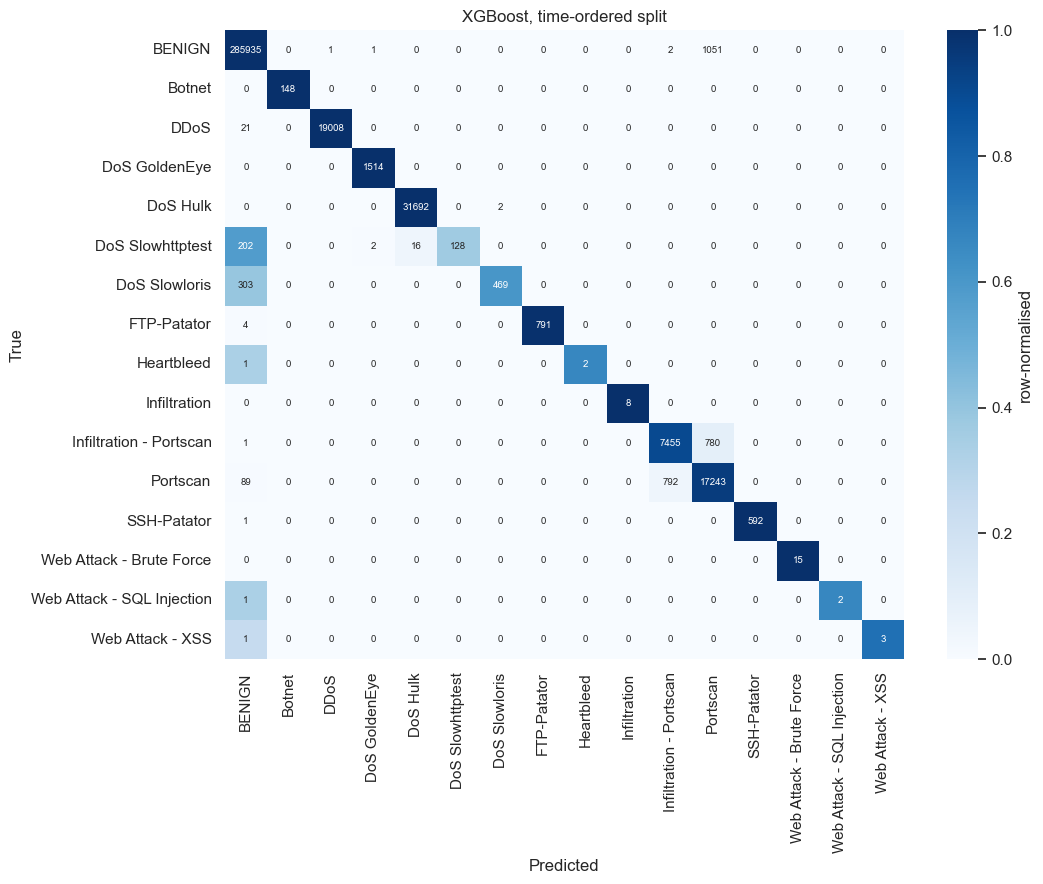

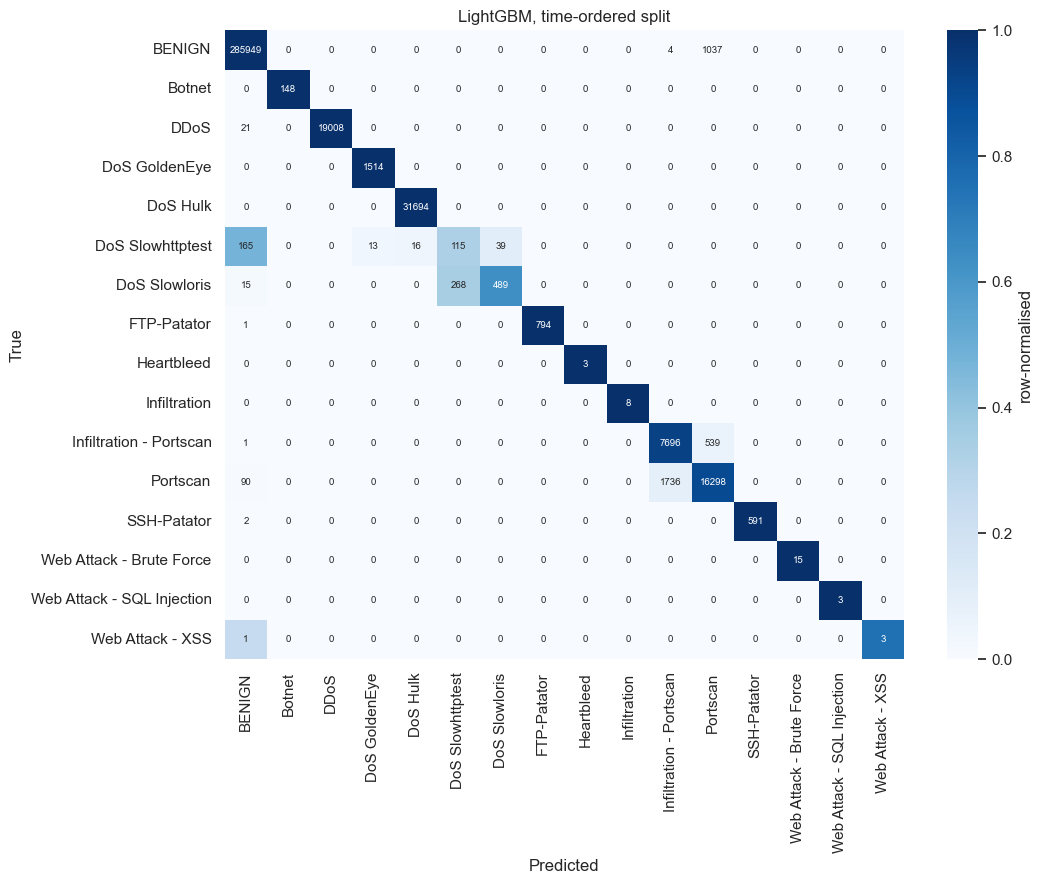

In [9]:
def plot_cm(split, name):
    te = SPLITS[split][1]
    cm = confusion_matrix(yall[te], preds[(split, name)], labels=enc.transform(LABELS))
    cmn = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(11, 9))
    sns.heatmap(cmn, annot=cm, fmt='d', cmap='Blues', vmin=0, vmax=1, xticklabels=LABELS, yticklabels=LABELS,
                annot_kws={'fontsize': 7}, cbar_kws={'label': 'row-normalised'}, ax=ax)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title(f'{name}, {split} split')
    plt.tight_layout(); plt.show()
for split in SPLITS:
    for name in make_models():
        plot_cm(split, name)

## 8. Feature importance (random split, tree models)

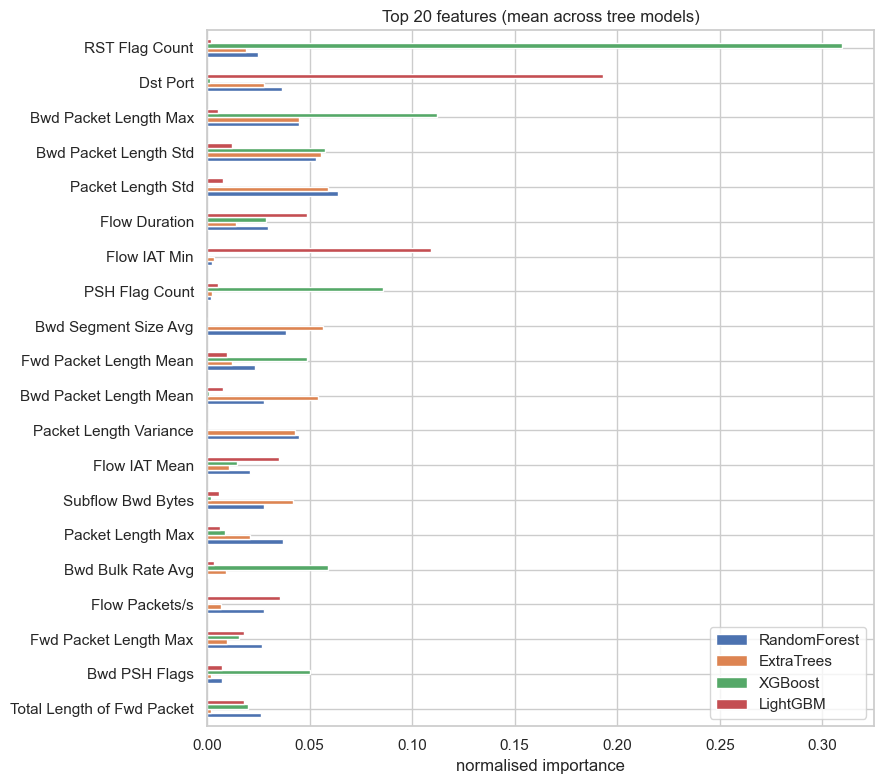

In [10]:
imp = {}
for name in ['RandomForest', 'ExtraTrees', 'XGBoost', 'LightGBM']:
    v = np.asarray(fitted[name].feature_importances_, dtype=float)
    imp[name] = v / v.sum()
imp = pd.DataFrame(imp, index=FEATURES)
top = imp.mean(axis=1).nlargest(20).index
ax = imp.loc[top[::-1]].plot.barh(figsize=(9, 8)); ax.set_xlabel('normalised importance')
ax.set_title('Top 20 features (mean across tree models)'); plt.tight_layout(); plt.show()

## 9. Results and interpretation

- **Required baseline:** Logistic Regression reaches **0.7969 macro F1** on the random split and **0.7278** on the time-ordered split. Interpreted correctly, the time-ordered score is the average F1 across all classes, with rare attacks weighted equally to benign traffic. The 0.0691 decline confirms that random splitting gives an optimistic estimate.
- **Best preliminary model:** HistGradientBoosting has the strongest time-ordered macro F1 at **0.9236**. Its random-split score is 0.9854, a 0.0618 decline under temporal evaluation.
- XGBoost achieves the highest random-split macro F1 (0.9858), but falls to 0.9108 on the stricter split. Model selection therefore changes when temporal generalization is prioritized.
- Weighted F1 remains above 0.98 for every time-ordered model because benign traffic dominates. Macro F1 and per-class metrics provide the more meaningful view.
- High-volume classes such as DDoS and DoS Hulk are detected reliably. The rarest classes, including Heartbleed, Infiltration, SQL Injection, and XSS, have only a few test observations, so their individual scores are unstable.
- The current evidence supports the research hypothesis that flow statistics can identify major attack families, but performance depends strongly on the validation design and the amount of class support.

## 10. Next steps for Module 24

- Tune the strongest time-aware model without using the test set.
- Test class weighting or resampling for rare attack families.
- Evaluate cross-year transfer from CICIDS2017 to CSE-CIC-IDS2018 after mapping compatible labels.
- Add probability calibration and precision-recall analysis for operational threshold selection.
- Compare feature importance with permutation importance or SHAP and check whether testbed-specific features dominate.
